In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

RESULTS_DIR = Path("results")
FIGURES_DIR = Path("figures")

FIGURES_DIR.mkdir(exist_ok=True)

analysis_df = pd.read_csv(
    RESULTS_DIR
    / "test_predictions_all_models.csv"
)

display(analysis_df.head())

print("Shape:", analysis_df.shape)

,Feature,Label,length,MLP_prediction,LSTM_prediction,Transformer_prediction,MLP_residual,MLP_absolute_error,LSTM_residual,LSTM_absolute_error,Transformer_residual,Transformer_absolute_error
0,CNINGKN,1.392,7,1.372281,1.354889,1.395338,-0.019719,0.019719,-0.037111,0.037111,0.003338,0.003338
1,NFHKG,1.915,5,1.885705,1.873995,1.867674,-0.029295,0.029295,-0.041005,0.041005,-0.047326,0.047326
2,DLDMYL,1.568,6,1.597368,1.573920,1.637321,0.029368,0.029368,0.005920,0.005920,0.069321,0.069321
3,VSHVNDL,1.812,7,1.755282,1.796223,1.764547,-0.056718,0.056718,-0.015777,0.015777,-0.047453,0.047453
4,ESNSTHGP,1.567,8,1.613197,1.588612,1.591401,0.046197,0.046197,0.021612,0.021612,0.024401,0.024401


Shape: (3997, 12)


In [2]:
MODEL_NAMES = [
    "MLP",
    "LSTM",
    "Transformer"
]

overall_results = []

for model_name in MODEL_NAMES:
    true_values = analysis_df["Label"]

    predictions = analysis_df[
        f"{model_name}_prediction"
    ]

    overall_results.append({
        "model":
            model_name,

        "MAE":
            mean_absolute_error(
                true_values,
                predictions
            ),

        "RMSE":
            mean_squared_error(
                true_values,
                predictions
            ) ** 0.5,

        "R2":
            r2_score(
                true_values,
                predictions
            )
    })

overall_results_df = (
    pd.DataFrame(overall_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(overall_results_df)

,model,MAE,RMSE,R2
0,Transformer,0.037922,0.048026,0.948265
1,LSTM,0.038476,0.048811,0.946558
2,MLP,0.041305,0.052538,0.938088


In [3]:
overall_results_df.to_csv(
    RESULTS_DIR
    / "neural_network_overall_metrics.csv",
    index=False
)

In [4]:
error_by_length_records = []

for model_name in MODEL_NAMES:
    grouped = (
        analysis_df
        .groupby("length")[
            f"{model_name}_absolute_error"
        ]
        .agg([
            "count",
            "mean",
            "median",
            "std"
        ])
        .reset_index()
    )

    grouped["model"] = model_name

    error_by_length_records.append(
        grouped
    )

error_by_length_df = pd.concat(
    error_by_length_records,
    ignore_index=True
)

display(error_by_length_df)

,length,count,mean,median,std,model
0,5,666,0.050012,0.043108,0.037688,MLP
1,6,611,0.044461,0.037218,0.033105,MLP
2,7,620,0.041612,0.035032,0.033523,MLP
3,8,651,0.040075,0.034674,0.031383,MLP
4,9,608,0.037264,0.032590,0.028755,MLP
5,10,841,0.035764,0.029487,0.028223,MLP
6,5,666,0.045843,0.037695,0.035381,LSTM
7,6,611,0.039747,0.032417,0.030776,LSTM
8,7,620,0.039687,0.033604,0.030580,LSTM
9,8,651,0.036739,0.031060,0.027760,LSTM


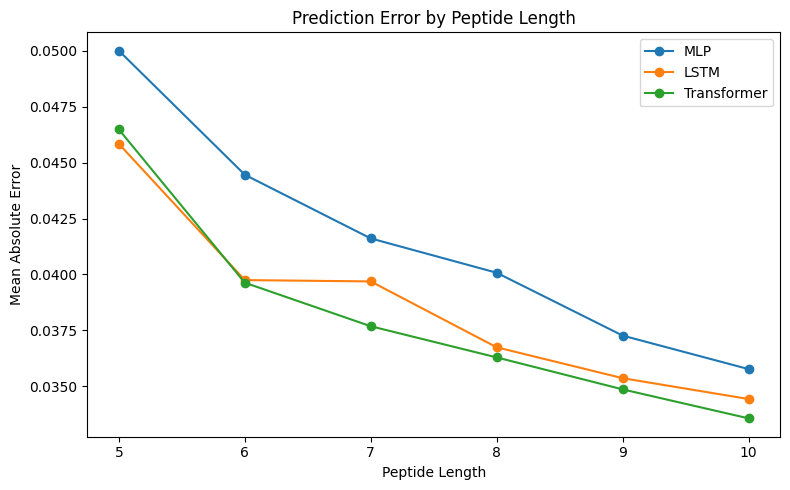

In [5]:
plt.figure(figsize=(8, 5))

for model_name in MODEL_NAMES:
    model_data = error_by_length_df[
        error_by_length_df["model"]
        == model_name
    ]

    plt.plot(
        model_data["length"],
        model_data["mean"],
        marker="o",
        label=model_name
    )

plt.xlabel("Peptide Length")
plt.ylabel("Mean Absolute Error")
plt.title("Prediction Error by Peptide Length")
plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "prediction_error_by_length.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [6]:
analysis_df["AP_group"] = pd.cut(
    analysis_df["Label"],
    bins=[
        -np.inf,
        1.4,
        1.8,
        np.inf
    ],
    labels=[
        "Low AP: < 1.4",
        "Middle AP: 1.4 - 1.8",
        "High AP: > 1.8"
    ]
)

print("Sample count by AP group:")

display(
    analysis_df["AP_group"]
    .value_counts()
    .sort_index()
)

Sample count by AP group:


AP_group
Low AP: < 1.4            243
Middle AP: 1.4 - 1.8    2132
High AP: > 1.8          1622
Name: count, dtype: int64

In [7]:
error_by_ap_group_records = []

for model_name in MODEL_NAMES:
    grouped = (
        analysis_df
        .groupby(
            "AP_group",
            observed=False
        )[
            f"{model_name}_absolute_error"
        ]
        .agg([
            "count",
            "mean",
            "median",
            "std"
        ])
        .reset_index()
    )

    grouped["model"] = model_name

    error_by_ap_group_records.append(
        grouped
    )

error_by_ap_group_df = pd.concat(
    error_by_ap_group_records,
    ignore_index=True
)

display(error_by_ap_group_df)

,AP_group,count,mean,median,std,model
0,Low AP: < 1.4,243,0.064622,0.055909,0.046222,MLP
1,Middle AP: 1.4 - 1.8,2132,0.036313,0.031385,0.027632,MLP
2,High AP: > 1.8,1622,0.044373,0.037456,0.033952,MLP
3,Low AP: < 1.4,243,0.043258,0.035125,0.035009,LSTM
4,Middle AP: 1.4 - 1.8,2132,0.033589,0.028735,0.025537,LSTM
5,High AP: > 1.8,1622,0.044183,0.037138,0.033419,LSTM
6,Low AP: < 1.4,243,0.043342,0.034136,0.036059,Transformer
7,Middle AP: 1.4 - 1.8,2132,0.033952,0.029241,0.025777,Transformer
8,High AP: > 1.8,1622,0.042328,0.036643,0.032079,Transformer


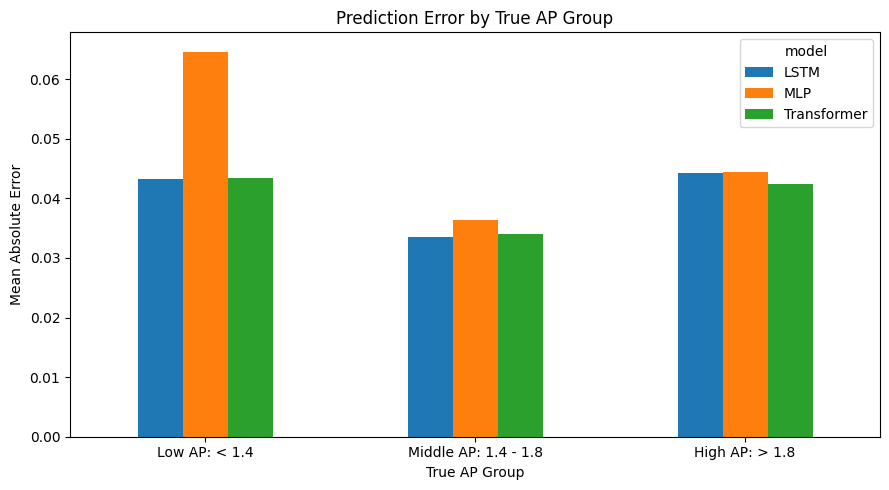

In [8]:
pivot_error_by_ap = (
    error_by_ap_group_df
    .pivot(
        index="AP_group",
        columns="model",
        values="mean"
    )
)

pivot_error_by_ap.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.xlabel("True AP Group")
plt.ylabel("Mean Absolute Error")
plt.title("Prediction Error by True AP Group")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "prediction_error_by_ap_group.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [9]:
residual_by_ap_group_records = []

for model_name in MODEL_NAMES:
    grouped = (
        analysis_df
        .groupby(
            "AP_group",
            observed=False
        )[
            f"{model_name}_residual"
        ]
        .agg([
            "count",
            "mean",
            "median",
            "std"
        ])
        .reset_index()
    )

    grouped["model"] = model_name

    residual_by_ap_group_records.append(
        grouped
    )

residual_by_ap_group_df = pd.concat(
    residual_by_ap_group_records,
    ignore_index=True
)

display(residual_by_ap_group_df)

,AP_group,count,mean,median,std,model
0,Low AP: < 1.4,243,0.043591,0.046984,0.066496,MLP
1,Middle AP: 1.4 - 1.8,2132,0.006868,0.006347,0.045118,MLP
2,High AP: > 1.8,1622,-0.014163,-0.015865,0.054058,MLP
3,Low AP: < 1.4,243,0.024987,0.023689,0.049776,LSTM
4,Middle AP: 1.4 - 1.8,2132,0.001672,0.002517,0.042167,LSTM
5,High AP: > 1.8,1622,-0.021712,-0.021508,0.050975,LSTM
6,Low AP: < 1.4,243,0.020221,0.015978,0.052688,Transformer
7,Middle AP: 1.4 - 1.8,2132,0.009818,0.010415,0.041488,Transformer
8,High AP: > 1.8,1622,-0.018521,-0.019337,0.049786,Transformer


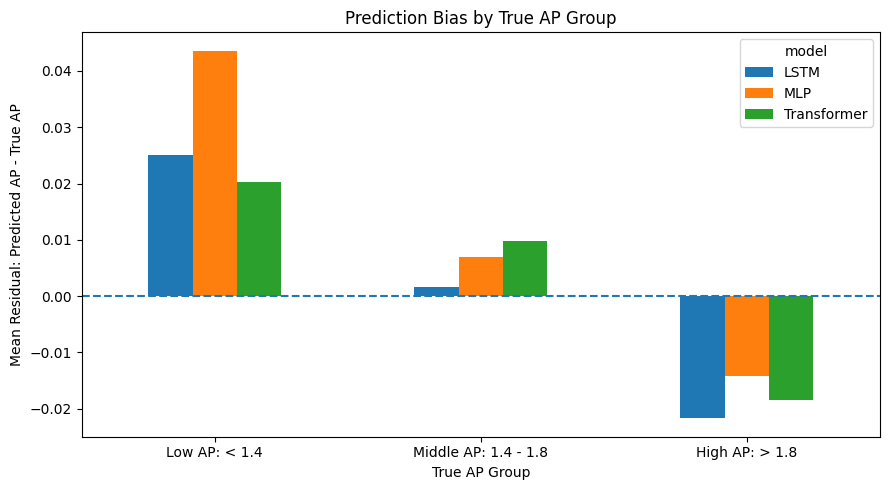

In [10]:
pivot_residual_by_ap = (
    residual_by_ap_group_df
    .pivot(
        index="AP_group",
        columns="model",
        values="mean"
    )
)

pivot_residual_by_ap.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("True AP Group")
plt.ylabel("Mean Residual: Predicted AP - True AP")
plt.title("Prediction Bias by True AP Group")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "prediction_bias_by_ap_group.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

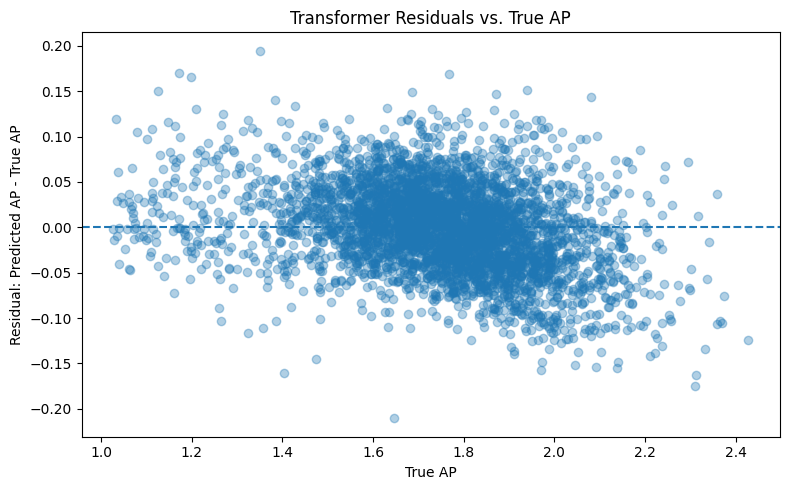

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(
    analysis_df["Label"],
    analysis_df[
        "Transformer_residual"
    ],
    alpha=0.35
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("True AP")
plt.ylabel("Residual: Predicted AP - True AP")
plt.title("Transformer Residuals vs. True AP")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "transformer_residuals_vs_true_ap.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [12]:
worst_transformer_predictions = (
    analysis_df[
        [
            "Feature",
            "Label",
            "length",
            "Transformer_prediction",
            "Transformer_residual",
            "Transformer_absolute_error"
        ]
    ]
    .sort_values(
        "Transformer_absolute_error",
        ascending=False
    )
    .head(20)
)

display(
    worst_transformer_predictions
)

,Feature,Label,length,Transformer_prediction,Transformer_residual,Transformer_absolute_error
3193,CAAPP,1.646,5,1.435567,-0.210433,0.210433
3415,AADGF,1.350,5,1.544607,0.194607,0.194607
373,YGPWP,2.310,5,2.135047,-0.174954,0.174954
3389,VQDMP,1.171,5,1.340870,0.169870,0.169870
3187,IPYGK,1.767,5,1.935402,0.168402,0.168402
277,DDPCNLEH,1.198,8,1.363638,0.165638,0.165638
2059,KYYQY,2.313,5,2.150085,-0.162915,0.162915
3975,AEGCL,1.404,5,1.243958,-0.160042,0.160042
2594,VVNMDRY,1.971,7,1.814134,-0.156866,0.156866
513,MHLLM,2.139,5,1.983978,-0.155022,0.155022


In [13]:
worst_transformer_predictions.to_csv(
    RESULTS_DIR
    / "worst_transformer_predictions.csv",
    index=False
)

In [14]:
analysis_df[
    "Transformer_improvement_over_LSTM"
] = (
    analysis_df[
        "LSTM_absolute_error"
    ]
    - analysis_df[
        "Transformer_absolute_error"
    ]
)

display(
    analysis_df[
        [
            "Feature",
            "Label",
            "length",
            "LSTM_prediction",
            "Transformer_prediction",
            "LSTM_absolute_error",
            "Transformer_absolute_error",
            "Transformer_improvement_over_LSTM"
        ]
    ]
    .sort_values(
        "Transformer_improvement_over_LSTM",
        ascending=False
    )
    .head(20)
)

,Feature,Label,length,LSTM_prediction,Transformer_prediction,LSTM_absolute_error,Transformer_absolute_error,Transformer_improvement_over_LSTM
1600,NVPNAM,1.477,6,1.336762,1.484694,0.140238,0.007694,0.132544
2160,LADRQ,1.233,5,1.349142,1.242183,0.116142,0.009183,0.106960
2074,LVRAN,1.198,5,1.324746,1.171560,0.126746,0.026440,0.100306
1225,MPQIEQ,1.146,6,1.278480,1.184377,0.132480,0.038377,0.094103
1772,GERMG,1.305,5,1.461155,1.370199,0.156155,0.065199,0.090956
346,GAYWA,2.012,5,1.920745,2.011232,0.091255,0.000768,0.090487
2810,CARAI,1.114,5,1.250914,1.163786,0.136914,0.049786,0.087127
925,EIDEVCQW,1.509,8,1.417383,1.504389,0.091617,0.004611,0.087006
2625,DCETLIK,1.530,7,1.428909,1.552867,0.101091,0.022867,0.078224
339,RELNPC,1.685,6,1.561250,1.639370,0.123750,0.045630,0.078120


In [15]:
analysis_df.to_csv(
    RESULTS_DIR
    / "test_error_analysis_all_models.csv",
    index=False
)

error_by_length_df.to_csv(
    RESULTS_DIR
    / "error_by_peptide_length.csv",
    index=False
)

error_by_ap_group_df.to_csv(
    RESULTS_DIR
    / "error_by_ap_group.csv",
    index=False
)

residual_by_ap_group_df.to_csv(
    RESULTS_DIR
    / "residual_bias_by_ap_group.csv",
    index=False
)

print("Error-analysis results saved.")

Error-analysis results saved.


In [16]:
label_statistics_by_length = (
    analysis_df
    .groupby("length")["Label"]
    .agg([
        "count",
        "mean",
        "std",
        "min",
        "max"
    ])
    .reset_index()
)

display(label_statistics_by_length)

,length,count,mean,std,min,max
0,5,666,1.787216,0.287251,1.036,2.428
1,6,611,1.777419,0.233438,1.027,2.374
2,7,620,1.728990,0.218753,1.037,2.223
3,8,651,1.701465,0.173987,1.034,2.094
4,9,608,1.687426,0.153820,1.071,2.124
5,10,841,1.774611,0.156031,1.066,2.223


In [17]:
transformer_error_by_length = (
    error_by_length_df[
        error_by_length_df["model"]
        == "Transformer"
    ]
    .copy()
)

transformer_normalized_error = (
    transformer_error_by_length
    .merge(
        label_statistics_by_length[
            ["length", "std"]
        ],
        on="length",
        suffixes=(
            "_error",
            "_label"
        )
    )
)

transformer_normalized_error[
    "normalized_MAE"
] = (
    transformer_normalized_error["mean"]
    / transformer_normalized_error["std_label"]
)

display(
    transformer_normalized_error[
        [
            "length",
            "count",
            "mean",
            "std_label",
            "normalized_MAE"
        ]
    ]
)

,length,count,mean,std_label,normalized_MAE
0,5,666,0.046487,0.287251,0.161833
1,6,611,0.039629,0.233438,0.169764
2,7,620,0.037682,0.218753,0.172257
3,8,651,0.036287,0.173987,0.208560
4,9,608,0.034856,0.153820,0.226602
5,10,841,0.033559,0.156031,0.215081


Among the evaluated neural-network models, the Transformer achieved the best predictive performance, with a test MAE of 0.0379, an RMSE of 0.0480, and an R
2
 of 0.9483. The Transformer slightly outperformed the LSTM, while both sequence-based models outperformed the MLP based on handcrafted features. These results suggest that token-level sequence modeling provides additional predictive value beyond global amino-acid composition, naïve positional encoding, and peptide length. However, the performance gap between Transformer and LSTM remains small, which is reasonable given that the peptide sequences contain only 5–10 amino acids.